# Day 1 · Notebook 2 — From two views to a video: monocular visual odometry

Visual SLAM front-ends (PTAM, ORB-SLAM, ...) run the same three steps over and over:

```
            ┌─────────────── for every new frame k ───────────────┐
 init  ──►  │  TRACK: match to the map, solve PnP  ->  pose of k  │
 (E, R, t)  │  MAP:   triangulate new matches       ->  new points │
            └──────────────────────────────────────────────────────┘
```

* **Initialise** once with the essential matrix (Notebook 1). This fixes the scale: first baseline = 1.
* **Track**: points from the map that are seen again give **2D–3D** matches, so the new pose comes from **PnP** (more on PnP in Day 2).
* **Map**: triangulate the new matches so the next frame has something to track.

Data: 17 frames (about 1 per second) from TUM RGB-D `fr3/long_office_household`, camera moving around a desk.

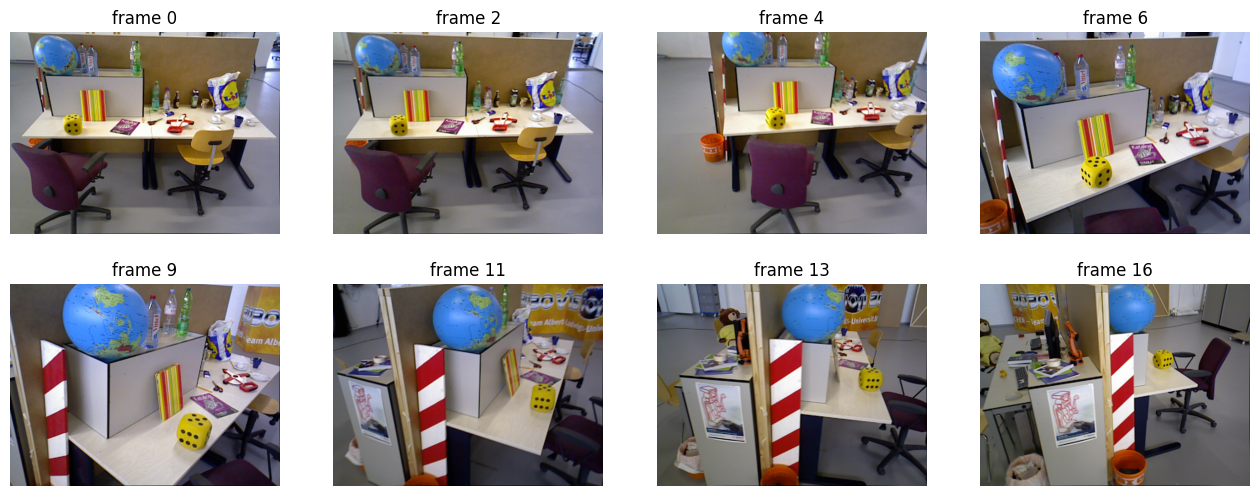

In [2]:
import shutil, subprocess
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))

def get_tum():
    d = DATA / "tum_fr3_office" / "rgb"
    if not d.exists():
        subprocess.run("git clone -q --depth 1 --filter=blob:none --sparse "
                       "https://github.com/magicleap/SuperGluePretrainedNetwork /tmp/sg_repo && "
                       "git -C /tmp/sg_repo sparse-checkout set assets/freiburg_sequence", shell=True, check=True)
        shutil.copytree("/tmp/sg_repo/assets/freiburg_sequence", d)
    return d

files = sorted(get_tum().glob("*.png"))
K = np.array([[535.4, 0, 320.1], [0, 539.2, 247.6], [0, 0, 1.0]])   # TUM fr3 intrinsics
rgbs = [cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB) for f in files]
grays = [cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) for im in rgbs]

fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, i in zip(axs.ravel(), np.linspace(0, len(files) - 1, 8).astype(int)):
    ax.imshow(rgbs[i]); ax.set_title(f"frame {i}"); ax.axis("off")
plt.show()

In [3]:
sift = cv2.SIFT_create(2000)
feats = [sift.detectAndCompute(g, None) for g in grays]
bf = cv2.BFMatcher(cv2.NORM_L2)

def match(i, j, ratio=0.75):
    """Ratio-test matches between frame i and j -> (idx_i, idx_j, pts_i, pts_j)."""
    knn = bf.knnMatch(feats[i][1], feats[j][1], k=2)
    m = [a for a, b in knn if a.distance < ratio * b.distance]
    qi = np.array([a.queryIdx for a in m]); ti = np.array([a.trainIdx for a in m])
    pi = np.float32([feats[i][0][q].pt for q in qi]); pj = np.float32([feats[j][0][t].pt for t in ti])
    return qi, ti, pi, pj

def to_T(R, t):
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = np.ravel(t); return T

def triangulate(T1, T2, p1, p2, max_err=2.0):
    """Triangulate, keep points in front of both cameras with small reprojection error."""
    X = cv2.triangulatePoints(K @ T1[:3], K @ T2[:3], p1.T, p2.T); X = (X[:3] / X[3]).T
    ok = np.ones(len(X), bool)
    for T, p in [(T1, p1), (T2, p2)]:
        Xc = (T[:3, :3] @ X.T + T[:3, 3:4])
        uv = (K @ Xc)[:2] / Xc[2]
        ok &= (Xc[2] > 0) & (np.linalg.norm(uv.T - p, axis=1) < max_err)
    return X, ok

## 1 · Initialise with the essential matrix (frames 0 → 1)

$T_k$ is **cam-from-world**: $\mathbf{X}_c = R_k\mathbf{X}_w + \mathbf{t}_k$. The camera centre is $\mathbf{C}_k = -R_k^\top\mathbf{t}_k$. Frame 0 defines the world: $T_0 = I$.

In [4]:
poses = [np.eye(4)]
qi, ti, p0, p1 = match(0, 1)
E, mask = cv2.findEssentialMat(p0, p1, K, cv2.RANSAC, 0.999, 1.0)
_, R, t, mask = cv2.recoverPose(E, p0, p1, K, mask=mask)
poses.append(to_T(R, t))
inl = mask.ravel() > 0
X, ok = triangulate(poses[0], poses[1], p0[inl], p1[inl])
# the "map": which keypoint of the LAST frame has which 3D point
map_of_last = {int(k): x for k, x, o in zip(ti[inl], X, ok) if o}
cloud, cloud_rgb = [X[ok]], [rgbs[1][p1[inl][ok, 1].astype(int), p1[inl][ok, 0].astype(int)]]
print(f"initial map: {len(map_of_last)} points, |t| = {np.linalg.norm(t):.2f} (scale is arbitrary!)")

initial map: 546 points, |t| = 1.00 (scale is arbitrary!)


## 2 · Track (PnP) + map (triangulate) for every new frame

For frame $k$, match it to frame $k-1$. Matches whose $k-1$ keypoint already has a 3D point give 2D–3D pairs $\{\mathbf{X}_j \leftrightarrow \mathbf{x}_j\}$. Then

$$ R_k, \mathbf{t}_k = \arg\min_{R,\mathbf{t}} \sum_j \big\| \pi\!\left(K (R\mathbf{X}_j + \mathbf{t})\right) - \mathbf{x}_j \big\|^2 $$

solved robustly with `solvePnPRansac`. Because the 3D points carry the scale from the initialisation, **every new pose has the same (arbitrary) scale**. Then triangulate all matches between $k-1$ and $k$ to refresh the map.

In [5]:
stats = []
for k in range(2, len(files)):
    qi, ti, pa, pb = match(k - 1, k)
    has3d = np.array([int(q) in map_of_last for q in qi])
    obj = np.array([map_of_last[int(q)] for q in qi[has3d]])
    img = pb[has3d]
    ok_pnp, rvec, tvec, inl = cv2.solvePnPRansac(obj, img, K, None, reprojectionError=2.0,
                                                 iterationsCount=1000, confidence=0.999)
    poses.append(to_T(cv2.Rodrigues(rvec)[0], tvec))
    X, ok = triangulate(poses[k - 1], poses[k], pa, pb)
    map_of_last = {int(t_): x for t_, x, o in zip(ti, X, ok) if o}
    cloud.append(X[ok]); cloud_rgb.append(rgbs[k][pb[ok, 1].astype(int), pb[ok, 0].astype(int)])
    stats.append((k, len(obj), len(inl), ok.sum()))
    print(f"frame {k:2d}: {len(obj):4d} 2D-3D matches, {len(inl):4d} PnP inliers, {ok.sum():4d} new points")

centers = np.array([-T[:3, :3].T @ T[:3, 3] for T in poses])

frame  2:  321 2D-3D matches,  258 PnP inliers,  470 new points
frame  3:  223 2D-3D matches,  145 PnP inliers,  350 new points
frame  4:  149 2D-3D matches,  122 PnP inliers,  256 new points
frame  5:  121 2D-3D matches,  105 PnP inliers,  259 new points
frame  6:  121 2D-3D matches,   86 PnP inliers,  263 new points
frame  7:  131 2D-3D matches,  105 PnP inliers,  297 new points
frame  8:  155 2D-3D matches,  135 PnP inliers,  388 new points
frame  9:  182 2D-3D matches,  168 PnP inliers,  382 new points
frame 10:  140 2D-3D matches,  128 PnP inliers,  275 new points
frame 11:   85 2D-3D matches,   72 PnP inliers,  226 new points
frame 12:   80 2D-3D matches,   51 PnP inliers,  231 new points
frame 13:   85 2D-3D matches,   73 PnP inliers,  257 new points
frame 14:   65 2D-3D matches,   56 PnP inliers,  175 new points
frame 15:   83 2D-3D matches,   65 PnP inliers,  235 new points
frame 16:  102 2D-3D matches,   88 PnP inliers,  338 new points


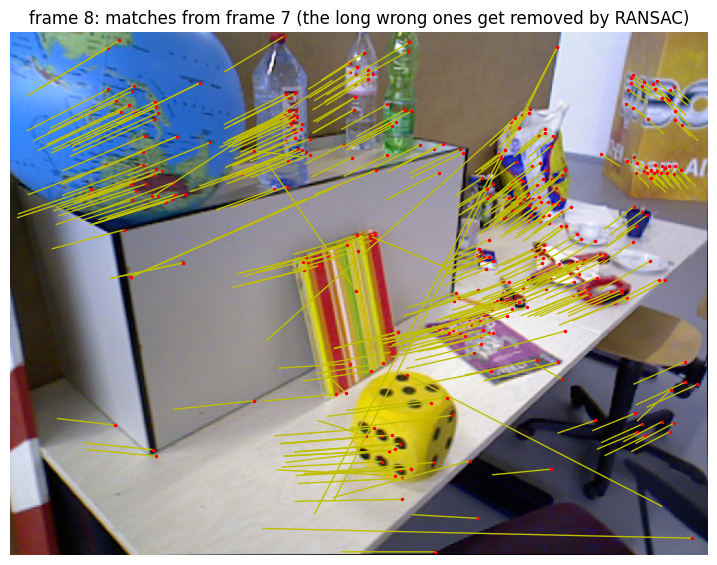

In [6]:
# What "tracking" looks like in the image: features of frame k matched to frame k-1
k = 8
qi, ti, pa, pb = match(k - 1, k)
plt.figure(figsize=(9, 7)); plt.imshow(rgbs[k])
for a, b in zip(pa, pb):
    plt.plot([a[0], b[0]], [a[1], b[1]], "y-", lw=1); plt.plot(b[0], b[1], "r.", ms=3)
plt.title(f"frame {k}: matches from frame {k-1} (the long wrong ones get removed by RANSAC)")
plt.axis("off"); plt.show()

In [7]:
P = np.concatenate(cloud); C = np.concatenate(cloud_rgb)
d = np.linalg.norm(P - np.median(P, 0), axis=1); keep = d < np.percentile(d, 90)
traces = [go.Scatter3d(x=P[keep, 0], y=P[keep, 1], z=P[keep, 2], mode="markers",
                       marker=dict(size=1.5, color=[f"rgb({r},{g},{b})" for r, g, b in C[keep]]), name="map points"),
          go.Scatter3d(x=centers[:, 0], y=centers[:, 1], z=centers[:, 2], mode="lines+markers",
                       line=dict(color="red", width=6), marker=dict(size=3), name="camera trajectory")]
fig = go.Figure(traces)
fig.update_layout(scene=dict(aspectmode="data", camera=dict(up=dict(x=0, y=-1, z=0))), height=650,
                  title="Monocular VO: trajectory + sparse map (units = first baseline)")
fig.show()

## 3 · Why VO alone is not enough: drift

Every pose is computed from the previous one, so small errors **accumulate**:

$$ T_k = \Delta T_k \,\Delta T_{k-1} \cdots \Delta T_1 \quad\Rightarrow\quad \text{error}(T_k) \text{ grows with } k $$

For a monocular camera the **scale** also drifts, because each new triangulation inherits the noise of the last one.

Below we add a tiny bit of noise to the image points and rerun the whole pipeline. Watch the end of the trajectory move.

**The fix (next notebook):** recognise a place you've seen before (**loop closure**) and optimise all poses together (**pose graph** / **bundle adjustment**). That's what turns VO into SLAM.

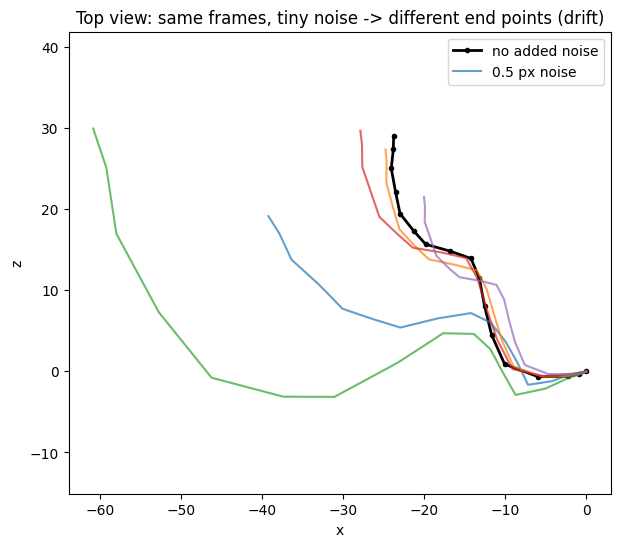

In [8]:
def run_vo(noise_px, seed):
    rng = np.random.default_rng(seed)
    jit = lambda p: (p + rng.normal(0, noise_px, p.shape)).astype(np.float32)
    qi, ti, p0, p1 = match(0, 1); p0, p1 = jit(p0), jit(p1)
    E, m = cv2.findEssentialMat(p0, p1, K, cv2.RANSAC, 0.999, 1.0)
    _, R, t, m = cv2.recoverPose(E, p0, p1, K, mask=m); inl = m.ravel() > 0
    Ts = [np.eye(4), to_T(R, t)]
    X, ok = triangulate(Ts[0], Ts[1], p0[inl], p1[inl], max_err=3)
    mp = {int(k): x for k, x, o in zip(ti[inl], X, ok) if o}
    for k in range(2, len(files)):
        qi, ti, pa, pb = match(k - 1, k); pa, pb = jit(pa), jit(pb)
        h = np.array([int(q) in mp for q in qi])
        _, rv, tv, _ = cv2.solvePnPRansac(np.array([mp[int(q)] for q in qi[h]]), pb[h], K, None,
                                          reprojectionError=3.0, iterationsCount=1000)
        Ts.append(to_T(cv2.Rodrigues(rv)[0], tv))
        X, ok = triangulate(Ts[k - 1], Ts[k], pa, pb, max_err=3)
        mp = {int(t_): x for t_, x, o in zip(ti, X, ok) if o}
    return np.array([-T[:3, :3].T @ T[:3, 3] for T in Ts])

plt.figure(figsize=(7, 6))
plt.plot(centers[:, 0], centers[:, 2], "k.-", lw=2, label="no added noise")
for s in range(5):
    c = run_vo(noise_px=0.5, seed=s)
    plt.plot(c[:, 0], c[:, 2], "-", alpha=0.7, label="0.5 px noise" if s == 0 else None)
plt.axis("equal"); plt.xlabel("x"); plt.ylabel("z"); plt.legend()
plt.title("Top view: same frames, tiny noise -> different end points (drift)"); plt.show()